# Sprint 3 — PLN: Geração de Linguagem Natural sobre Alertas

**FIAP × Forzy — Grupo CodeX** · Gêmeo Digital para motores elétricos industriais

Guilherme Gama (RM565293) · Bruno Fernandes Nascimento (RM552574) · Edgar Lódula de Assis (RM565260) · Júlia Aben-Athar (RM566325) · Igor Thiago Nakajima Vieira (RM563632)

A camada de ML entrega número; o operador precisa de frase. Este notebook faz a conversão: **resumos de alerta** em três níveis (§3–4), **classificação dos eventos** de manutenção (§6) e **relatório operacional** rastreável (§7), com avaliação por ROUGE e checklist (§5).


## 1. Ambiente

Roda em CPU. No Colab, suba a pasta `nlp/` completa e execute em ordem.


In [1]:
# Colab: descomente a linha abaixo na primeira execução
# !pip -q install rouge-score transformers torch scikit-learn pandas matplotlib

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "pln").exists() and (RAIZ.parent / "pln").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

DADOS = RAIZ / "dados"
RELATORIOS = RAIZ / "relatorios"
RELATORIOS.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
print("raiz do projeto:", RAIZ)

raiz do projeto: F:\FIAP\Segundo Ano\Challenge Sprints\challenge-sprint-4\processamento-linguagem-natural


## 2. Dados de entrada

Gerados por `scripts/gerar_leituras_alertas.py` e `scripts/gerar_eventos.py` (semente fixa): séries de sensor, alertas detectados, eventos rotulados e os gabaritos manuais de ROUGE.

Os 7 primeiros dias são o baseline; nos 7 últimos as falhas são injetadas — sobrecarga no MT-003 e desalinhamento no MT-008 (críticos), desvios menores nos demais. MT-004 e MT-006 servem de contraprova.


In [2]:
leituras = pd.read_csv(DADOS / "leituras_sensores.csv")
alertas = json.loads((DADOS / "alertas.json").read_text(encoding="utf-8"))["alertas"]
eventos = pd.read_csv(DADOS / "eventos_operacionais.csv")
referencias = {r["alerta_id"]: r["resumo_referencia"] for r in
               json.loads((DADOS / "alertas_referencia.json").read_text(encoding="utf-8"))["referencias"]}

print(f"leituras: {leituras.shape[0]} linhas x {leituras.shape[1]} colunas")
print(f"alertas : {len(alertas)}")
print(f"eventos : {len(eventos)}")
leituras.head(3)

leituras: 2688 linhas x 10 colunas
alertas : 24
eventos : 168


,ativo_id,tag,timestamp,temperatura_enrolamento_c,temperatura_mancal_c,corrente_a,tensao_v,rotacao_rpm,vibracao_mm_s,fator_potencia
0,MT-001,W22-100L-2P-3CV-1F,2026-06-01 00:00:00,58.73,46.90,12.58,219.4,3513.2,1.89,0.817
1,MT-001,W22-100L-2P-3CV-1F,2026-06-01 01:00:00,59.99,47.47,12.64,221.2,3512.3,2.00,0.819
2,MT-001,W22-100L-2P-3CV-1F,2026-06-01 02:00:00,58.93,46.97,12.88,221.9,3513.8,1.85,0.815


In [3]:
df_alertas = pd.DataFrame(alertas)
resumo_sev = (df_alertas.groupby(["severidade", "sensor"]).size()
              .unstack(fill_value=0)
              .reindex(["critico", "moderado", "leve"]))
display(resumo_sev)
print(df_alertas["severidade"].value_counts().reindex(["critico", "moderado", "leve"]).to_string())

sensor,corrente_a,fator_potencia,rotacao_rpm,temperatura_enrolamento_c,temperatura_mancal_c,tensao_v,vibracao_mm_s
severidade,,,,,,,
critico,1,0,0,1,1,0,1
moderado,0,1,1,2,2,1,1
leve,7,0,0,1,0,2,2


severidade
critico      4
moderado     8
leve        12


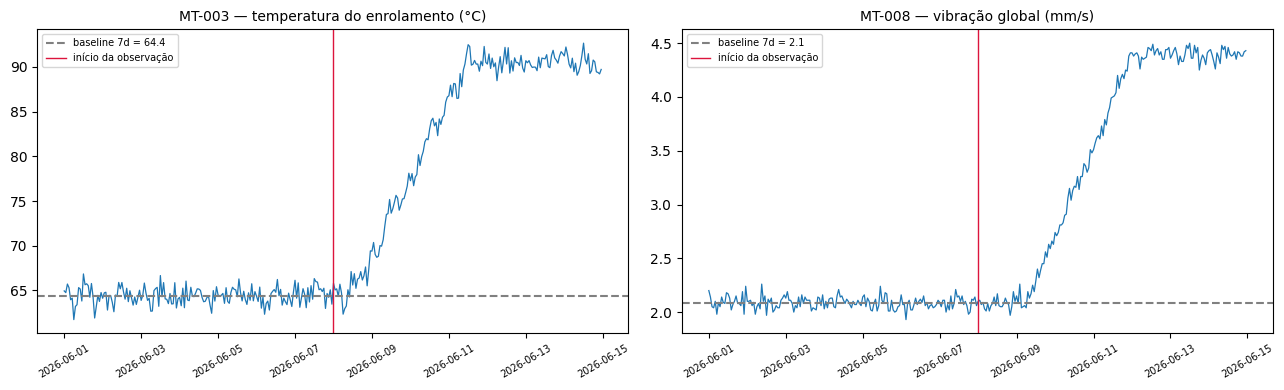

In [4]:
# Visualizacao das series que originaram os dois alertas criticos
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
lt = leituras.copy()
lt["timestamp"] = pd.to_datetime(lt["timestamp"])

for eixo, (ativo, sensor, titulo) in zip(eixos, [
        ("MT-003", "temperatura_enrolamento_c", "MT-003 — temperatura do enrolamento (°C)"),
        ("MT-008", "vibracao_mm_s", "MT-008 — vibração global (mm/s)")]):
    s = lt[lt["ativo_id"] == ativo]
    eixo.plot(s["timestamp"], s[sensor], linewidth=0.9)
    corte = s["timestamp"].min() + pd.Timedelta(days=7)
    base = s[s["timestamp"] < corte][sensor].mean()
    eixo.axhline(base, linestyle="--", color="gray", label=f"baseline 7d = {base:.1f}")
    eixo.axvline(corte, color="crimson", linewidth=1, label="início da observação")
    eixo.set_title(titulo, fontsize=10)
    eixo.tick_params(axis="x", rotation=30, labelsize=7)
    eixo.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 3. Templates de narrativa

Seis templates, dois por nível de urgência. Cada nível tem léxico próprio e cada grandeza tem recomendação tabelada — o texto nunca propõe procedimento fora do domínio do ativo.


In [5]:
from pln.narrativa import (LEXICO, RECOMENDACOES, TEMPLATES, gerar_resumo,
                          gerar_resumos, templates_por_severidade)

# corpo completo de cada template (o marcador `acima_abaixo` é resolvido em
# tempo de renderização para "acima" ou "abaixo", conforme o sinal do desvio)
for t in TEMPLATES:
    print(f"[{t.template_id}] ({t.severidade})")
    print(t.corpo)
    print()

[T-LEVE-01] (leve)
{abertura} no motor {tag} ({localizacao}). {artigo_cap} {sensor_rotulo} {verbo_desvio} de {magnitude} em relação ao baseline de {baseline} {periodo}, sem ultrapassar os limites operacionais. {urgencia}: {recomendacao}.

[T-LEVE-02] (leve)
{tag} sob observação: {sensor_rotulo} em {valor_atual} contra {baseline} de referência ({magnitude}), {periodo}. Desvio de baixa criticidade — {recomendacao}.

[T-MOD-01] (moderado)
{abertura} no motor {tag} ({localizacao}). {artigo_cap} {sensor_rotulo} {verbo_desvio} de {magnitude} acima_abaixo do baseline {periodo}, atingindo {valor_atual}. {urgencia} {prazo}: {recomendacao}.

[T-MOD-02] (moderado)
{abertura}: {tag} opera com {sensor_rotulo} em {valor_atual}, desvio {magnitude} sobre a referência de {baseline} {periodo}. Causa provável sob avaliação: {causa_provavel}. {urgencia} {prazo}.

[T-CRIT-01] (critico)
{abertura} — motor {tag} ({localizacao}). {artigo_cap} {sensor_rotulo} {verbo_desvio} de {magnitude} sobre o baseline de {

In [6]:
# Tabela de recomendações: uma por (grandeza, severidade) — o texto gerado
# nunca propõe procedimento fora desta tabela
pd.DataFrame(RECOMENDACOES).T[["leve", "moderado", "critico"]]

,leve,moderado,critico
temperatura_enrolamento_c,verificar limpeza das aletas e obstruções no fluxo de ar,verificação do sistema de refrigeração e conferência da carga acionada,reduzir carga e inspecionar refrigeração e isolamento do enrolamento
temperatura_mancal_c,conferir nível e validade da graxa na próxima rota de lubrificação,inspeção do mancal e revisão do plano de lubrificação,parada para inspeção do mancal e substituição do rolamento
corrente_a,confrontar a leitura com o regime de carga do processo,verificação da carga acionada e do equilíbrio entre fases,avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime
tensao_v,registrar a ocorrência no acompanhamento de qualidade de energia,verificação do barramento de alimentação e das conexões do painel,acionar a equipe elétrica para avaliação imediata da alimentação
rotacao_rpm,confirmar a estabilidade da carga acoplada,verificação do escorregamento e da carga aplicada ao eixo,avaliar travamento mecânico ou perda de torque antes de religar
vibracao_mm_s,incluir o ativo na próxima coleta de análise de vibração,medição de vibração dedicada e conferência de alinhamento,"parada para verificação de alinhamento, balanceamento e rolamentos"
fator_potencia,acompanhar o regime de carga durante o turno,verificação do regime de carga e do banco de capacitores,avaliação imediata da correção de reativo da instalação


In [7]:
pd.DataFrame(LEXICO).T[["abertura", "verbo_desvio", "urgencia", "prazo"]]

,abertura,verbo_desvio,urgencia,prazo
leve,Registro informativo,apresentou variação,Nenhuma ação imediata requerida,acompanhar na próxima ronda
moderado,Alerta moderado detectado,apresentou desvio,Recomenda-se verificação programada,dentro das próximas 24 horas
critico,ALERTA CRÍTICO,atingiu desvio severo,Intervenção imediata requerida,acionar manutenção no turno corrente


## 4. Geração dos resumos

As variantes de cada nível são alternadas para o painel não repetir a mesma frase. Todo resumo termina com o bloco de rastreabilidade `[ALT-00X | sensor | pico | baseline | janela]`.


In [8]:
resumos = gerar_resumos(alertas)
df_resumos = pd.DataFrame(resumos)
df_resumos["resumo_referencia"] = df_resumos["alerta_id"].map(referencias)

for sev in ("critico", "moderado", "leve"):
    exemplo = next(r for r in resumos if r["severidade"] == sev)
    print(f"### {sev.upper()}  ({exemplo['template_id']})")
    print(exemplo["texto"])
    print()

### CRITICO  (T-CRIT-01)
ALERTA CRÍTICO — motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A corrente de linha atingiu desvio severo de +25,7% sobre o baseline de 72,1 A de forma sustentada por 5,6 dias, com valor de pico em 90,7 A. Risco de atuação das proteções e parada não programada. Intervenção imediata requerida: avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime — acionar manutenção no turno corrente. [ALT-001 | sensor: corrente_a | pico: 11/06 às 12h00 | baseline 7d = 72,1 A | janela movel: 3h]

### MODERADO  (T-MOD-01)
Alerta moderado detectado no motor W22-100L-2P-3CV-1F (Linha de Produção A — Bomba Centrífuga 01). A temperatura do mancal apresentou desvio de +9,9 C acima do baseline nas últimas 6 horas, atingindo 55,8 C. Recomenda-se verificação programada dentro das próximas 24 horas: inspeção do mancal e revisão do plano de lubrificação. [ALT-005 | sensor: temperatura_mancal_c | pico: 10/06 às 22h00 | baseline 7d = 46,7 C | janela movel: 

In [9]:
# Mesmo alerta renderizado nas duas variantes do seu nivel
alerta_demo = next(a for a in alertas if a["severidade"] == "moderado")
for v in range(len(templates_por_severidade("moderado"))):
    print(f"-- variante {v}")
    print(gerar_resumo(alerta_demo, variante=v, com_rastreio=False)["texto"], "\n")

-- variante 0
Alerta moderado detectado no motor W22-100L-2P-3CV-1F (Linha de Produção A — Bomba Centrífuga 01). A temperatura do mancal apresentou desvio de +9,9 C acima do baseline nas últimas 6 horas, atingindo 55,8 C. Recomenda-se verificação programada dentro das próximas 24 horas: inspeção do mancal e revisão do plano de lubrificação. 

-- variante 1
Alerta moderado detectado: W22-100L-2P-3CV-1F opera com temperatura do mancal em 55,8 C, desvio +9,9 C sobre a referência de 46,7 C nas últimas 6 horas. Causa provável sob avaliação: lubrificação ou pré-carga do rolamento. Recomenda-se verificação programada dentro das próximas 24 horas. 



In [10]:
df_resumos[["alerta_id", "severidade", "template_id", "texto_sem_rastreio"]].head(24)

,alerta_id,severidade,template_id,texto_sem_rastreio
0,ALT-001,critico,T-CRIT-01,ALERTA CRÍTICO — motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A corrente de linha atingiu desvio sev...
1,ALT-002,critico,T-CRIT-02,"ALERTA CRÍTICO: W22-160L-2P-30CV-3F em condição severa. Leitura de temperatura do enrolamento registrada em 92,3 C (..."
2,ALT-003,critico,T-CRIT-01,ALERTA CRÍTICO — motor W22-112M-4P-7.5CV-3F (Linha de Produção B — Misturador Industrial). A temperatura do mancal a...
3,ALT-004,critico,T-CRIT-02,"ALERTA CRÍTICO: W22-112M-4P-7.5CV-3F em condição severa. Leitura de vibração global registrada em 4,4 mm/s (+112,8% ..."
4,ALT-005,moderado,T-MOD-01,Alerta moderado detectado no motor W22-100L-2P-3CV-1F (Linha de Produção A — Bomba Centrífuga 01). A temperatura do ...
5,ALT-006,moderado,T-MOD-02,"Alerta moderado detectado: W22-100L-2P-3CV-1F opera com tensão de alimentação em 230,1 V, desvio +4,5% sobre a refer..."
6,ALT-007,moderado,T-MOD-01,Alerta moderado detectado no motor W22-132M-4P-15CV-3F (Área 3 — Compressor Principal). A temperatura do enrolamento...
7,ALT-008,moderado,T-MOD-02,"Alerta moderado detectado: W22-160L-2P-30CV-3F opera com rotação do eixo em 3472,5 RPM, desvio -1,9% sobre a referên..."
8,ALT-009,moderado,T-MOD-01,Alerta moderado detectado no motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A temperatura do mancal ap...
9,ALT-010,moderado,T-MOD-02,"Alerta moderado detectado: W22-225S-4P-75CV-3F opera com vibração global em 4,4 mm/s, desvio +62,8% sobre a referênc..."


## 5. Avaliação dos resumos

### 5.1 ROUGE contra referências manuais

24 resumos escritos à mão a partir dos números, **sem** consultar os templates. ROUGE próximo de 1 aqui indicaria gabarito contaminado, não qualidade.


In [11]:
from pln import avaliacao as av

df_rouge = av.calcular_rouge(df_resumos["texto_sem_rastreio"],
                             df_resumos["resumo_referencia"],
                             df_resumos["alerta_id"])
display(av.resumo_rouge(df_rouge))
display(av.resumo_rouge(df_rouge, df_resumos["severidade"]))

,media_f1
rouge1_f,0.5498
rouge2_f,0.2962
rougeL_f,0.4053


,rouge1_f,rouge2_f,rougeL_f
_grupo,,,
critico,0.5654,0.2960,0.4054
leve,0.5458,0.3001,0.4339
moderado,0.5481,0.2906,0.3624


In [12]:
comparacao = df_rouge.merge(
    df_resumos[["alerta_id", "severidade", "texto_sem_rastreio", "resumo_referencia"]],
    left_on="id", right_on="alerta_id")
linha = comparacao.sort_values("rouge1_f", ascending=False).iloc[0]
print(f"melhor par ({linha['alerta_id']}, ROUGE-1 F1 = {linha['rouge1_f']}):\n")
print("GERADO   :", linha["texto_sem_rastreio"], "\n")
print("REFERENCIA:", linha["resumo_referencia"])

melhor par (ALT-016, ROUGE-1 F1 = 0.7654):

GERADO   : W22-132M-4P-15CV-3F sob observação: vibração global em 2,5 mm/s contra 2,2 mm/s de referência (+25,8%), em leitura pontual. Desvio de baixa criticidade — incluir o ativo na próxima coleta de análise de vibração. 

REFERENCIA: Leitura pontual de vibracao acima do usual no motor W22-132M-4P-15CV-3F: 2,49 mm/s contra 2,19 mm/s de referencia (+25,8%). Desvio leve e isolado; incluir o ativo na proxima coleta de analise de vibracao.


### 5.2 Checklist de clareza, precisão e utilidade

Dez critérios objetivos (`pln/avaliacao.py`): tamanho e legibilidade, identificação do ativo e da grandeza, direção do desvio, recomendação, tom de urgência, rastreabilidade e **anti-alucinação numérica** — todo número da frase é conferido contra o registro de alerta.


In [13]:
df_check = av.aplicar_checklist(resumos, alertas)
display(av.taxa_aprovacao(df_check).to_frame("aprovação (%)"))
print("score médio do checklist:", round(df_check["score_checklist"].mean(), 3))
print("tamanho médio (palavras):", round(df_check["n_palavras"].mean(), 1))
df_check.head(8)

,aprovação (%)
clareza_tamanho,100.0
clareza_frases_curtas,100.0
clareza_sem_placeholder,100.0
precisao_identifica_ativo,100.0
precisao_identifica_grandeza,100.0
precisao_sem_numero_alucinado,100.0
precisao_direcao_do_desvio,100.0
utilidade_recomendacao,100.0
utilidade_tom_de_urgencia,100.0
rastreabilidade_fonte,100.0


score médio do checklist: 1.0
tamanho médio (palavras): 46.0


,alerta_id,severidade,template_id,n_palavras,clareza_tamanho,clareza_frases_curtas,clareza_sem_placeholder,precisao_identifica_ativo,precisao_identifica_grandeza,precisao_sem_numero_alucinado,precisao_direcao_do_desvio,utilidade_recomendacao,utilidade_tom_de_urgencia,rastreabilidade_fonte,numeros_invalidos,score_checklist
0,ALT-001,critico,T-CRIT-01,69,True,True,True,True,True,True,True,True,True,True,,1.0
1,ALT-002,critico,T-CRIT-02,47,True,True,True,True,True,True,True,True,True,True,,1.0
2,ALT-003,critico,T-CRIT-01,68,True,True,True,True,True,True,True,True,True,True,,1.0
3,ALT-004,critico,T-CRIT-02,44,True,True,True,True,True,True,True,True,True,True,,1.0
4,ALT-005,moderado,T-MOD-01,50,True,True,True,True,True,True,True,True,True,True,,1.0
5,ALT-006,moderado,T-MOD-02,45,True,True,True,True,True,True,True,True,True,True,,1.0
6,ALT-007,moderado,T-MOD-01,50,True,True,True,True,True,True,True,True,True,True,,1.0
7,ALT-008,moderado,T-MOD-02,43,True,True,True,True,True,True,True,True,True,True,,1.0


## 6. Classificação textual dos eventos operacionais

168 registros de manutenção rotulados em cinco categorias: corretiva, preventiva, anomalia elétrica, anomalia mecânica e operação normal. Oito são ambíguos de propósito.

Três abordagens no mesmo split 60/40: **zero-shot** (mDeBERTa XNLI, sem treino), **baseline supervisionado** (TF-IDF + Regressão Logística) e o **híbrido** da §6.2. A verbalização das classes foi escolhida comparando três formulações em `scripts/tunar_verbalizacao.py` (0,60 vs. 0,52 vs. 0,50).


In [14]:
from pln import classificacao as cls

print("categorias:", cls.CATEGORIAS)
pd.DataFrame([{"categoria": c, "hipótese zero-shot": cls.HIPOTESE.format(cls.ROTULOS_ZERO_SHOT[c])}
              for c in cls.CATEGORIAS])

categorias: ('manutencao_corretiva', 'manutencao_preventiva', 'anomalia_eletrica', 'anomalia_mecanica', 'operacao_normal')


,categoria,hipótese zero-shot
0,manutencao_corretiva,O texto trata de conserto apos quebra.
1,manutencao_preventiva,O texto trata de inspecao programada.
2,anomalia_eletrica,O texto trata de problema eletrico.
3,anomalia_mecanica,O texto trata de problema mecanico.
4,operacao_normal,O texto trata de funcionamento normal.


In [15]:
display(eventos["categoria_gold"].value_counts().to_frame("registros"))
eventos.sample(6, random_state=7)[["evento_id", "origem", "texto", "categoria_gold", "ambiguo"]]

,registros
categoria_gold,
anomalia_eletrica,34
manutencao_preventiva,34
anomalia_mecanica,34
operacao_normal,33
manutencao_corretiva,33


,evento_id,origem,texto,categoria_gold,ambiguo
123,EV-124,diario_de_bordo,Revisao programada do acoplamento com verificacao de desgaste do elastomero.,manutencao_preventiva,0
164,EV-165,diario_de_bordo,Inspecao visual programada realizada. Sem anormalidades nas conexoes e na carcaca.,manutencao_preventiva,0
86,EV-087,diario_de_bordo,"Corrente desequilibrada entre fases em 9 por cento, acima do limite de 5 por cento.",anomalia_eletrica,0
98,EV-099,ordem_servico,Aumento do ruido eletrico no sinal de corrente coletado pelo supervisorio.,anomalia_eletrica,0
146,EV-147,supervisorio,Folga percebida na base do motor com movimento visivel durante a partida.,anomalia_mecanica,0
159,EV-160,supervisorio,"Rotacao de 1755 RPM medida, coerente com o valor nominal do motor.",operacao_normal,0


In [16]:
# Normalizacao herdada da Sprint 1: NFKD + expansao de abreviacoes, sem stemming
exemplo = eventos["texto"].iloc[0]
print("original  :", exemplo)
print("normalizado:", cls.normalizar(exemplo))

original  : Painel acusando falha de fase intermitente durante a operacao do misturador.
normalizado: painel acusando falha de fase intermitente durante a operacao do misturador.


In [17]:
from sklearn.model_selection import train_test_split

treino, teste = train_test_split(eventos, test_size=0.4, random_state=42,
                                 stratify=eventos["categoria_gold"])
pipe = cls.construir_baseline()
pipe.fit(treino["texto"].map(cls.normalizar), treino["categoria_gold"])
pred_base = pipe.predict(teste["texto"].map(cls.normalizar))
av_base = cls.avaliar(teste["categoria_gold"], pred_base, nome="tfidf_logreg")
print("macro-F1 baseline:", av_base["macro_f1"])

macro-F1 baseline: 0.7626


### 6.1 Inferência zero-shot

Custa alguns minutos em CPU; o resultado fica em `relatorios/classificacao_zero_shot.csv`. Para refazer, mude `RECOMPUTAR = True`.


In [18]:
RECOMPUTAR = False
caminho_zs = RELATORIOS / "classificacao_zero_shot.csv"

if RECOMPUTAR or not caminho_zs.exists():
    classificador = cls.carregar_zero_shot()
    pred_zs = cls.classificar_zero_shot(eventos["texto"].tolist(), classificador)
    pred_zs.insert(0, "evento_id", eventos["evento_id"].values)
    pred_zs["categoria_gold"] = eventos["categoria_gold"].values
    pred_zs["ambiguo"] = eventos["ambiguo"].values
    pred_zs.to_csv(caminho_zs, index=False, encoding="utf-8")
else:
    pred_zs = pd.read_csv(caminho_zs)

zs_teste = pred_zs[pred_zs["evento_id"].isin(teste["evento_id"])]
av_zs = cls.avaliar(zs_teste["categoria_gold"], zs_teste["pred"], nome="zero_shot_mdeberta")
av_zs_total = cls.avaliar(pred_zs["categoria_gold"], pred_zs["pred"], nome="zero_shot_total_168")
print("macro-F1 zero-shot (teste):", av_zs["macro_f1"])
print("macro-F1 zero-shot (168 registros):", av_zs_total["macro_f1"])

macro-F1 zero-shot (teste): 0.6032
macro-F1 zero-shot (168 registros): 0.6038


### 6.2 Híbrido: zero-shot + regras de intervenção

O zero-shot confunde sintoma com intervenção: *"trocado o retentor do mancal após contaminação da graxa"* cai em `anomalia_mecanica`. A correção é lexical — predição `anomalia_*` com verbo de intervenção (*trocado*, *substituído*, *reparo*) vira manutenção.

> As regras foram desenhadas a partir dos erros deste corpus, então parte do ganho é ajuste ao conjunto.


In [19]:
pred_zs["pred_hibrido"] = cls.ajustar_por_regras(pred_zs)
zs_teste = pred_zs[pred_zs["evento_id"].isin(teste["evento_id"])]
av_hibrido = cls.avaliar(zs_teste["categoria_gold"], zs_teste["pred_hibrido"],
                         nome="zero_shot+regras")
av_hibrido_total = cls.avaliar(pred_zs["categoria_gold"], pred_zs["pred_hibrido"],
                               nome="zero_shot+regras_total")
print("macro-F1 híbrido (teste):", av_hibrido["macro_f1"])
print("macro-F1 híbrido (168 registros):", av_hibrido_total["macro_f1"])

macro-F1 híbrido (teste): 0.8377
macro-F1 híbrido (168 registros): 0.7975


### 6.3 F1 por categoria e matriz de confusão

In [20]:
display(cls.tabela_f1(av_zs, av_hibrido, av_base))
display(cls.matriz_confusao_df(av_zs))
display(cls.matriz_confusao_df(av_hibrido))
display(cls.matriz_confusao_df(av_base))

,zero_shot_mdeberta,zero_shot+regras,tfidf_logreg
manutencao_corretiva,0.143,0.963,0.741
manutencao_preventiva,0.667,0.783,0.759
anomalia_eletrica,0.759,0.786,0.929
anomalia_mecanica,0.591,0.800,0.690
operacao_normal,0.857,0.857,0.696
MACRO-F1,0.603,0.838,0.763


,pred:manutencao_corretiva,pred:manutencao_preventiva,pred:anomalia_eletrica,pred:anomalia_mecanica,pred:operacao_normal
real:manutencao_corretiva,1,0,1,11,0
real:manutencao_preventiva,0,7,3,3,1
real:anomalia_eletrica,0,0,11,2,1
real:anomalia_mecanica,0,0,0,13,1
real:operacao_normal,0,0,0,1,12


,pred:manutencao_corretiva,pred:manutencao_preventiva,pred:anomalia_eletrica,pred:anomalia_mecanica,pred:operacao_normal
real:manutencao_corretiva,13,0,0,0,0
real:manutencao_preventiva,0,9,3,1,1
real:anomalia_eletrica,0,0,11,2,1
real:anomalia_mecanica,1,0,0,12,1
real:operacao_normal,0,0,0,1,12


,pred:manutencao_corretiva,pred:manutencao_preventiva,pred:anomalia_eletrica,pred:anomalia_mecanica,pred:operacao_normal
real:manutencao_corretiva,10,1,0,2,0
real:manutencao_preventiva,2,11,0,1,0
real:anomalia_eletrica,0,0,13,0,1
real:anomalia_mecanica,1,2,0,10,1
real:operacao_normal,1,1,1,2,8


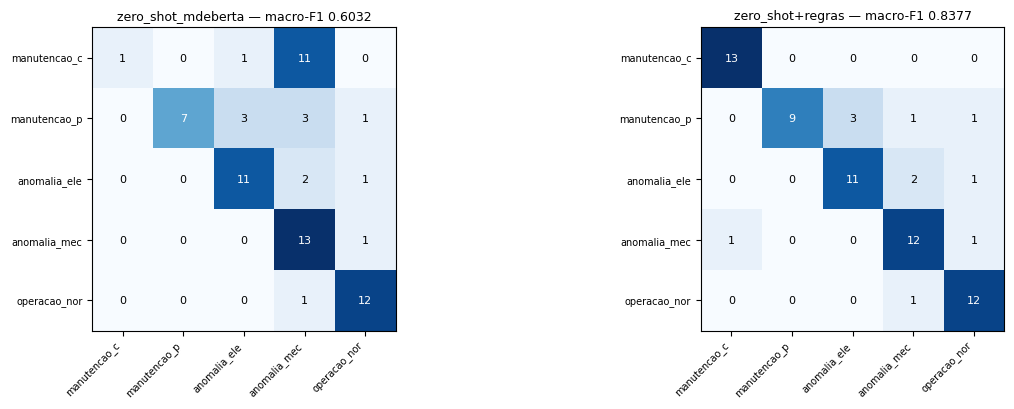

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
for eixo, avaliacao in zip(eixos, (av_zs, av_hibrido)):
    m = np.array(avaliacao["matriz_confusao"])
    eixo.imshow(m, cmap="Blues")
    eixo.set_xticks(range(len(cls.CATEGORIAS)))
    eixo.set_yticks(range(len(cls.CATEGORIAS)))
    eixo.set_xticklabels([c[:12] for c in cls.CATEGORIAS], rotation=45, ha="right", fontsize=7)
    eixo.set_yticklabels([c[:12] for c in cls.CATEGORIAS], fontsize=7)
    eixo.set_title(f"{avaliacao['nome']} — macro-F1 {avaliacao['macro_f1']}", fontsize=9)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            eixo.text(j, i, m[i, j], ha="center", va="center", fontsize=8,
                      color="white" if m[i, j] > m.max() / 2 else "black")
plt.tight_layout()
plt.show()

In [22]:
# Erros do zero-shot: onde a fronteira entre categorias vizinhas quebra
erros_zs = cls.erros(pred_zs.merge(eventos[["evento_id", "texto"]].rename(
    columns={"texto": "texto_original"}), on="evento_id"))
print(f"{len(erros_zs)} erros em {len(pred_zs)} registros "
      f"({len(erros_zs)/len(pred_zs):.1%})")
print("erros em registros ambíguos:", int(erros_zs["ambiguo"].sum()) if "ambiguo" in erros_zs else 0)
erros_zs.head(12)

62 erros em 168 registros (36.9%)
erros em registros ambíguos: 4


,evento_id,texto,categoria_gold,pred,score,ambiguo
0,EV-001,Painel acusando falha de fase intermitente durante a operacao do misturador.,anomalia_eletrica,anomalia_mecanica,0.554200,0
2,EV-003,Trocado o retentor do mancal traseiro apos contaminacao da graxa por agua de lavagem.,manutencao_corretiva,anomalia_mecanica,0.528110,0
6,EV-007,Realizada a troca completa dos rolamentos LA e LOA apos falha catastrofica em operacao.,manutencao_corretiva,anomalia_mecanica,0.491064,0
10,EV-011,Executada rota de lubrificacao automatizada. Doseador reabastecido com graxa Mobil XHP 222.,manutencao_preventiva,manutencao_corretiva,0.382724,0
13,EV-014,Rotacao oscilando 2 por cento abaixo do nominal com carga constante.,anomalia_mecanica,operacao_normal,0.415575,0
15,EV-016,Calibracao anual dos sensores de temperatura do enrolamento efetuada pelo laboratorio.,manutencao_preventiva,anomalia_mecanica,0.509836,0
16,EV-017,Substituicao do enrolamento apos queima da fase S. Motor enviado para rebobinamento na oficina externa.,manutencao_corretiva,anomalia_mecanica,0.494742,0
20,EV-021,Aplicada rotina preventiva de reaperto eletrico nos terminais com torquimetro.,manutencao_preventiva,anomalia_eletrica,0.622932,0
21,EV-022,Feito reparo provisorio na caixa de ligacao ate a chegada da peca definitiva.,manutencao_corretiva,anomalia_eletrica,0.669546,0
22,EV-023,Rele de sobrecarga atuando de forma intermitente sem sobrecarga mecanica aparente.,anomalia_eletrica,operacao_normal,0.591210,0


,valor
limiar,0.5000
fracao_baixa_confianca,0.2321
score_medio,0.6925
score_mediano,0.7106


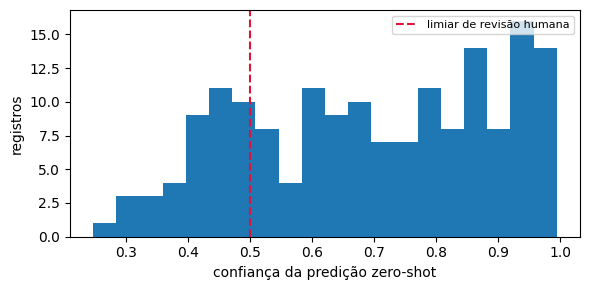

In [23]:
display(pd.Series(cls.distribuicao_confianca(pred_zs)).to_frame("valor"))
fig, eixo = plt.subplots(figsize=(6, 3))
eixo.hist(pred_zs["score"], bins=20)
eixo.axvline(0.5, color="crimson", linestyle="--", label="limiar de revisão humana")
eixo.set_xlabel("confiança da predição zero-shot")
eixo.set_ylabel("registros")
eixo.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Relatório operacional em linguagem natural

Diário (24 h) e semanal (7 dias), com resumo executivo, alertas, equipamentos em risco, tendências e recomendações.

Nenhuma afirmação entra sem âncora de origem: `[ALT-...]` para alertas, `[FONTE: leituras_sensores.csv | ...]` para frases derivadas da série. Um alerta entra no período quando o **episódio** se sobrepõe à janela, não só quando o pico cai nela.


In [24]:
from pln.relatorio import calcular_tendencias, gerar_relatorio

eventos_class = pred_zs.merge(eventos[["evento_id", "ativo_id"]], on="evento_id", how="left")
eventos_class["pred"] = eventos_class["pred_hibrido"]   # predição final
relatorio_semanal = gerar_relatorio(alertas, leituras, periodo="semanal",
                                    eventos_classificados=eventos_class)
relatorio_diario = gerar_relatorio(alertas, leituras, periodo="diario")

(RELATORIOS / "relatorio_semanal.md").write_text(relatorio_semanal, encoding="utf-8")
(RELATORIOS / "relatorio_diario.md").write_text(relatorio_diario, encoding="utf-8")

from IPython.display import Markdown
Markdown(relatorio_semanal)

# Relatório Operacional Semanal — Frota de Motores Elétricos

**Período analisado:** 07/06/2026 23:00 a 14/06/2026 23:00  
**Ativos monitorados:** 8  
**Gerado automaticamente pelo módulo PLN (Sprint 3)** — cada afirmação referencia o dado de sensor de origem.

## 1. Resumo executivo

Foram emitidos **24 alertas** no período: 4 críticos, 8 moderados e 12 leves. 2 equipamento(s) em risco, 4 em observação e 0 sem desvio detectado no período.

Prioridade do turno: **MT-003, MT-008** — alertas críticos abertos.

| Ativo | Estado operacional | Alertas (C/M/L) | Sensores envolvidos |
|-------|--------------------|-----------------|---------------------|
| MT-001 | EM OBSERVAÇÃO | 0/2/0 | temperatura do mancal, tensão de alimentação |
| MT-002 | EM OBSERVAÇÃO | 0/1/4 | corrente de linha, temperatura do enrolamento, vibração global |
| MT-003 | EM RISCO | 2/2/1 | corrente de linha, rotação do eixo, temperatura do enrolamento, temperatura do mancal |
| MT-004 | ESTÁVEL COM DESVIO | 0/0/2 | corrente de linha, vibração global |
| MT-005 | EM OBSERVAÇÃO | 0/1/2 | corrente de linha, tensão de alimentação, vibração global |
| MT-006 | ESTÁVEL COM DESVIO | 0/0/1 | tensão de alimentação |
| MT-007 | EM OBSERVAÇÃO | 0/2/1 | corrente de linha, fator de potência, temperatura do enrolamento |
| MT-008 | EM RISCO | 2/0/1 | temperatura do enrolamento, temperatura do mancal, vibração global |

## 2. Alertas emitidos

### 2.1 Severidade critico (4)

- ALERTA CRÍTICO — motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A corrente de linha atingiu desvio severo de +25,7% sobre o baseline de 72,1 A de forma sustentada por 5,6 dias, com valor de pico em 90,7 A. Risco de atuação das proteções e parada não programada. Intervenção imediata requerida: avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime — acionar manutenção no turno corrente. [ALT-001 | sensor: corrente_a | pico: 11/06 às 12h00 | baseline 7d = 72,1 A | janela movel: 3h]
- ALERTA CRÍTICO: W22-160L-2P-30CV-3F em condição severa. Leitura de temperatura do enrolamento registrada em 92,3 C (+27,7 C vs. baseline) de forma sustentada por 6 dias. Intervenção imediata requerida — reduzir carga e inspecionar refrigeração e isolamento do enrolamento. Manter o ativo sob supervisão contínua até a intervenção. [ALT-002 | sensor: temperatura_enrolamento_c | pico: 11/06 às 13h00 | baseline 7d = 64,4 C | janela movel: 3h]
- ALERTA CRÍTICO — motor W22-112M-4P-7.5CV-3F (Linha de Produção B — Misturador Industrial). A temperatura do mancal atingiu desvio severo de +17,8 C sobre o baseline de 49,8 C de forma sustentada por 5,1 dias, com valor de pico em 67,1 C. Risco de falha do rolamento por perda de lubrificação. Intervenção imediata requerida: parada para inspeção do mancal e substituição do rolamento — acionar manutenção no turno corrente. [ALT-003 | sensor: temperatura_mancal_c | pico: 13/06 às 14h00 | baseline 7d = 49,8 C | janela movel: 3h]
- ALERTA CRÍTICO: W22-112M-4P-7.5CV-3F em condição severa. Leitura de vibração global registrada em 4,4 mm/s (+112,8% vs. baseline) de forma sustentada por 5 dias. Intervenção imediata requerida — parada para verificação de alinhamento, balanceamento e rolamentos. Manter o ativo sob supervisão contínua até a intervenção. [ALT-004 | sensor: vibracao_mm_s | pico: 12/06 às 15h00 | baseline 7d = 2,1 mm/s | janela movel: 6h]

### 2.2 Severidade moderado (8)

- Alerta moderado detectado no motor W22-100L-2P-3CV-1F (Linha de Produção A — Bomba Centrífuga 01). A temperatura do mancal apresentou desvio de +9,9 C acima do baseline nas últimas 6 horas, atingindo 55,8 C. Recomenda-se verificação programada dentro das próximas 24 horas: inspeção do mancal e revisão do plano de lubrificação. [ALT-005 | sensor: temperatura_mancal_c | pico: 10/06 às 22h00 | baseline 7d = 46,7 C | janela movel: 3h]
- Alerta moderado detectado: W22-100L-2P-3CV-1F opera com tensão de alimentação em 230,1 V, desvio +4,5% sobre a referência de 220,1 V de forma sustentada por 4,1 dias. Causa provável sob avaliação: qualidade de energia no barramento de alimentação. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-006 | sensor: tensao_v | pico: 11/06 às 20h00 | baseline 7d = 220,1 V | janela movel: 3h]
- Alerta moderado detectado no motor W22-132M-4P-15CV-3F (Área 3 — Compressor Principal). A temperatura do enrolamento apresentou desvio de +18,8 C acima do baseline de forma sustentada por 5,2 dias, atingindo 82 C. Recomenda-se verificação programada dentro das próximas 24 horas: verificação do sistema de refrigeração e conferência da carga acionada. [ALT-007 | sensor: temperatura_enrolamento_c | pico: 12/06 às 15h00 | baseline 7d = 63,5 C | janela movel: 3h]
- Alerta moderado detectado: W22-160L-2P-30CV-3F opera com rotação do eixo em 3472,5 RPM, desvio -1,9% sobre a referência de 3541,7 RPM de forma sustentada por 5,6 dias. Causa provável sob avaliação: escorregamento por variação de carga. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-008 | sensor: rotacao_rpm | pico: 14/06 às 01h00 | baseline 7d = 3541,7 RPM | janela movel: 3h]
- Alerta moderado detectado no motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A temperatura do mancal apresentou desvio de +9,2 C acima do baseline de forma sustentada por 4,7 dias, atingindo 61,7 C. Recomenda-se verificação programada dentro das próximas 24 horas: inspeção do mancal e revisão do plano de lubrificação. [ALT-009 | sensor: temperatura_mancal_c | pico: 13/06 às 15h00 | baseline 7d = 52,8 C | janela movel: 3h]
- Alerta moderado detectado: W22-225S-4P-75CV-3F opera com vibração global em 4,4 mm/s, desvio +62,8% sobre a referência de 2,7 mm/s nas últimas 8 horas. Causa provável sob avaliação: desalinhamento, desbalanceamento ou desgaste de rolamento. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-010 | sensor: vibracao_mm_s | pico: 13/06 às 06h00 | baseline 7d = 2,7 mm/s | janela movel: 6h]
- Alerta moderado detectado no motor WMagnet-IPM-50CV-3F (Linha de Produção A — Extrusora Principal). O fator de potência apresentou desvio de -0,08 abaixo do baseline de forma sustentada por 4,8 dias, atingindo 0,88. Recomenda-se verificação programada dentro das próximas 24 horas: verificação do regime de carga e do banco de capacitores. [ALT-011 | sensor: fator_potencia | pico: 14/06 às 19h00 | baseline 7d = 0,95 | janela movel: 6h]
- Alerta moderado detectado: WMagnet-IPM-50CV-3F opera com temperatura do enrolamento em 75,1 C, desvio +13,7 C sobre a referência de 61,5 C nas últimas 8 horas. Causa provável sob avaliação: sistema de refrigeração ou carga acima do regime. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-012 | sensor: temperatura_enrolamento_c | pico: 11/06 às 17h00 | baseline 7d = 61,5 C | janela movel: 3h]

### 2.3 Severidade leve (12)

- Registro informativo no motor W22-132M-4P-15CV-3F (Área 3 — Compressor Principal). A corrente de linha apresentou variação de +7,1% em relação ao baseline de 39 A nas últimas 18 horas, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: confrontar a leitura com o regime de carga do processo. [ALT-013 | sensor: corrente_a | pico: 11/06 às 15h00 | baseline 7d = 39 A | janela movel: 3h]
- W22-132M-4P-15CV-3F sob observação: corrente de linha em 42,2 A contra 39 A de referência (+7%), nas últimas 4 horas. Desvio de baixa criticidade — confrontar a leitura com o regime de carga do processo. [ALT-014 | sensor: corrente_a | pico: 14/06 às 12h00 | baseline 7d = 39 A | janela movel: 3h]
- Registro informativo no motor W22-132M-4P-15CV-3F (Área 3 — Compressor Principal). A corrente de linha apresentou variação de +6,2% em relação ao baseline de 39 A nas últimas 18 horas, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: confrontar a leitura com o regime de carga do processo. [ALT-015 | sensor: corrente_a | pico: 12/06 às 14h00 | baseline 7d = 39 A | janela movel: 3h]
- W22-132M-4P-15CV-3F sob observação: vibração global em 2,5 mm/s contra 2,2 mm/s de referência (+25,8%), em leitura pontual. Desvio de baixa criticidade — incluir o ativo na próxima coleta de análise de vibração. [ALT-016 | sensor: vibracao_mm_s | pico: 13/06 às 17h00 | baseline 7d = 2,2 mm/s | janela movel: 6h]
- Registro informativo no motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A corrente de linha apresentou variação de +5,8% em relação ao baseline de 72,1 A em leitura pontual, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: confrontar a leitura com o regime de carga do processo. [ALT-017 | sensor: corrente_a | pico: 09/06 às 02h00 | baseline 7d = 72,1 A | janela movel: 3h]
- W22-80-4P-1CV-3F sob observação: corrente de linha em 3,4 A contra 3,1 A de referência (+11,7%), nas últimas 5 horas. Desvio de baixa criticidade — confrontar a leitura com o regime de carga do processo. [ALT-018 | sensor: corrente_a | pico: 09/06 às 19h00 | baseline 7d = 3,1 A | janela movel: 3h]
- Registro informativo no motor W22-80-4P-1CV-3F (Linha de Produção B — Esteira Transportadora 02). A vibração global apresentou variação de +35,7% em relação ao baseline de 1,2 mm/s nas últimas 4 horas, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: incluir o ativo na próxima coleta de análise de vibração. [ALT-019 | sensor: vibracao_mm_s | pico: 12/06 às 05h00 | baseline 7d = 1,2 mm/s | janela movel: 6h]
- W22-225S-4P-75CV-3F sob observação: corrente de linha em 111,9 A contra 104,2 A de referência (+8,3%), de forma sustentada por 4,3 dias. Desvio de baixa criticidade — confrontar a leitura com o regime de carga do processo. [ALT-020 | sensor: corrente_a | pico: 13/06 às 10h00 | baseline 7d = 104,2 A | janela movel: 3h]
- Registro informativo no motor W22-225S-4P-75CV-3F (Área 5 — Moinho de Bolas). A tensão de alimentação apresentou variação de -3,4% em relação ao baseline de 380,1 V de forma sustentada por 4,2 dias, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: registrar a ocorrência no acompanhamento de qualidade de energia. [ALT-021 | sensor: tensao_v | pico: 11/06 às 11h00 | baseline 7d = 380,1 V | janela movel: 3h]
- W22-90L-6P-2CV-3F sob observação: tensão de alimentação em 215,8 V contra 219,9 V de referência (-2,2%), nas últimas 2 horas. Desvio de baixa criticidade — registrar a ocorrência no acompanhamento de qualidade de energia. [ALT-022 | sensor: tensao_v | pico: 12/06 às 14h00 | baseline 7d = 219,9 V | janela movel: 3h]
- Registro informativo no motor WMagnet-IPM-50CV-3F (Linha de Produção A — Extrusora Principal). A corrente de linha apresentou variação de +10,1% em relação ao baseline de 69,4 A de forma sustentada por 4,6 dias, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: confrontar a leitura com o regime de carga do processo. [ALT-023 | sensor: corrente_a | pico: 11/06 às 12h00 | baseline 7d = 69,4 A | janela movel: 3h]
- W22-112M-4P-7.5CV-3F sob observação: temperatura do enrolamento em 72,7 C contra 62,4 C de referência (+10,4 C), de forma sustentada por 4,4 dias. Desvio de baixa criticidade — verificar limpeza das aletas e obstruções no fluxo de ar. [ALT-024 | sensor: temperatura_enrolamento_c | pico: 13/06 às 13h00 | baseline 7d = 62,4 C | janela movel: 3h]

## 3. Equipamentos em risco

**MT-003 — W22-160L-2P-30CV-3F** (Área 3 — Ventilador de Exaustão) — estado **EM RISCO**: requer intervenção no turno corrente. Grandezas afetadas: corrente de linha, rotação do eixo, temperatura do enrolamento, temperatura do mancal. Alerta de maior severidade: ALT-001, corrente de linha em 90,7 A contra baseline de 72,1 A (11/06 às 12h00). [ALERTAS: ALT-001, ALT-002, ALT-008, ALT-009, ALT-017]

**MT-008 — W22-112M-4P-7.5CV-3F** (Linha de Produção B — Misturador Industrial) — estado **EM RISCO**: requer intervenção no turno corrente. Grandezas afetadas: temperatura do enrolamento, temperatura do mancal, vibração global. Alerta de maior severidade: ALT-003, temperatura do mancal em 67,1 C contra baseline de 49,8 C (13/06 às 14h00). [ALERTAS: ALT-003, ALT-004, ALT-024]

**MT-001 — W22-100L-2P-3CV-1F** (Linha de Produção A — Bomba Centrífuga 01) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: temperatura do mancal, tensão de alimentação. Alerta de maior severidade: ALT-005, temperatura do mancal em 55,8 C contra baseline de 46,7 C (10/06 às 22h00). [ALERTAS: ALT-005, ALT-006]

**MT-002 — W22-132M-4P-15CV-3F** (Área 3 — Compressor Principal) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: corrente de linha, temperatura do enrolamento, vibração global. Alerta de maior severidade: ALT-007, temperatura do enrolamento em 82 C contra baseline de 63,5 C (12/06 às 15h00). [ALERTAS: ALT-007, ALT-013, ALT-014, ALT-015, ALT-016]

**MT-005 — W22-225S-4P-75CV-3F** (Área 5 — Moinho de Bolas) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: corrente de linha, tensão de alimentação, vibração global. Alerta de maior severidade: ALT-010, vibração global em 4,4 mm/s contra baseline de 2,7 mm/s (13/06 às 06h00). [ALERTAS: ALT-010, ALT-020, ALT-021]

**MT-007 — WMagnet-IPM-50CV-3F** (Linha de Produção A — Extrusora Principal) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: corrente de linha, fator de potência, temperatura do enrolamento. Alerta de maior severidade: ALT-011, fator de potência em 0,88 contra baseline de 0,95 (14/06 às 19h00). [ALERTAS: ALT-011, ALT-012, ALT-023]

## 4. Tendências observadas

- MT-003: tendência de queda da rotação do eixo a 10,47 RPM/dia (3539,7 RPM -> 3475,7 RPM). [FONTE: leituras_sensores.csv | MT-003 | rotacao_rpm | 07/06-14/06 | n=169]
- MT-003: tendência de alta da temperatura do enrolamento a 4,23 C/dia (63,5 C -> 89,7 C). [FONTE: leituras_sensores.csv | MT-003 | temperatura_enrolamento_c | 07/06-14/06 | n=169]
- MT-008: tendência de alta da temperatura do mancal a 3,21 C/dia (49,9 C -> 67,4 C). [FONTE: leituras_sensores.csv | MT-008 | temperatura_mancal_c | 07/06-14/06 | n=169]
- MT-002: tendência de alta da temperatura do enrolamento a 2,82 C/dia (64,8 C -> 78,9 C). [FONTE: leituras_sensores.csv | MT-002 | temperatura_enrolamento_c | 07/06-14/06 | n=169]
- MT-003: tendência de alta da corrente de linha a 2,77 A/dia (71,9 A -> 90,3 A). [FONTE: leituras_sensores.csv | MT-003 | corrente_a | 07/06-14/06 | n=169]
- MT-005: tendência de queda da tensão de alimentação a 2,14 V/dia (379,4 V -> 368 V). [FONTE: leituras_sensores.csv | MT-005 | tensao_v | 07/06-14/06 | n=169]
- MT-008: tendência de alta da temperatura do enrolamento a 1,73 C/dia (61,9 C -> 70,9 C). [FONTE: leituras_sensores.csv | MT-008 | temperatura_enrolamento_c | 07/06-14/06 | n=169]
- MT-003: tendência de alta da temperatura do mancal a 1,29 C/dia (54,1 C -> 61,7 C). [FONTE: leituras_sensores.csv | MT-003 | temperatura_mancal_c | 07/06-14/06 | n=169]

## 5. Eventos registrados (classificação automática)

168 registros textuais processados pelo classificador de eventos no histórico do período, distribuídos em: anomalia mecanica (45), operacao normal (35), manutencao corretiva (33), anomalia eletrica (33), manutencao preventiva (22). [FONTE: eventos_operacionais.csv | classificador zero-shot]

## 6. Recomendações preliminares

| Prazo | Ativo | Ação recomendada | Origem |
|-------|-------|------------------|--------|
| IMEDIATO | MT-003 | avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime | ALT-001 (corrente_a) |
| IMEDIATO | MT-003 | reduzir carga e inspecionar refrigeração e isolamento do enrolamento | ALT-002 (temperatura_enrolamento_c) |
| IMEDIATO | MT-008 | parada para inspeção do mancal e substituição do rolamento | ALT-003 (temperatura_mancal_c) |
| IMEDIATO | MT-008 | parada para verificação de alinhamento, balanceamento e rolamentos | ALT-004 (vibracao_mm_s) |
| 24 h | MT-001 | inspeção do mancal e revisão do plano de lubrificação | ALT-005 (temperatura_mancal_c) |
| 24 h | MT-001 | verificação do barramento de alimentação e das conexões do painel | ALT-006 (tensao_v) |
| 24 h | MT-002 | verificação do sistema de refrigeração e conferência da carga acionada | ALT-007 (temperatura_enrolamento_c) |
| 24 h | MT-003 | verificação do escorregamento e da carga aplicada ao eixo | ALT-008 (rotacao_rpm) |
| 24 h | MT-003 | inspeção do mancal e revisão do plano de lubrificação | ALT-009 (temperatura_mancal_c) |
| 24 h | MT-005 | medição de vibração dedicada e conferência de alinhamento | ALT-010 (vibracao_mm_s) |
| 24 h | MT-007 | verificação do regime de carga e do banco de capacitores | ALT-011 (fator_potencia) |
| 24 h | MT-007 | verificação do sistema de refrigeração e conferência da carga acionada | ALT-012 (temperatura_enrolamento_c) |
| próxima ronda | MT-002 | confrontar a leitura com o regime de carga do processo | ALT-013 (corrente_a) |
| próxima ronda | MT-002 | incluir o ativo na próxima coleta de análise de vibração | ALT-016 (vibracao_mm_s) |
| próxima ronda | MT-004 | confrontar a leitura com o regime de carga do processo | ALT-018 (corrente_a) |
| próxima ronda | MT-004 | incluir o ativo na próxima coleta de análise de vibração | ALT-019 (vibracao_mm_s) |
| próxima ronda | MT-005 | confrontar a leitura com o regime de carga do processo | ALT-020 (corrente_a) |
| próxima ronda | MT-005 | registrar a ocorrência no acompanhamento de qualidade de energia | ALT-021 (tensao_v) |
| próxima ronda | MT-006 | registrar a ocorrência no acompanhamento de qualidade de energia | ALT-022 (tensao_v) |
| próxima ronda | MT-007 | confrontar a leitura com o regime de carga do processo | ALT-023 (corrente_a) |
| próxima ronda | MT-008 | verificar limpeza das aletas e obstruções no fluxo de ar | ALT-024 (temperatura_enrolamento_c) |

---

*Relatório gerado por `pln.relatorio.gerar_relatorio`. Baseline = média das leituras dos 7 dias anteriores ao período de observação. Alertas derivados de média móvel vs. baseline, conforme `scripts/gerar_leituras_alertas.py`.*

### 7.1 Relatório diário

In [25]:
Markdown(relatorio_diario)

# Relatório Operacional Diário — Frota de Motores Elétricos

**Período analisado:** 13/06/2026 23:00 a 14/06/2026 23:00  
**Ativos monitorados:** 8  
**Gerado automaticamente pelo módulo PLN (Sprint 3)** — cada afirmação referencia o dado de sensor de origem.

## 1. Resumo executivo

Foram emitidos **14 alertas** no período: 4 críticos, 5 moderados e 5 leves. 2 equipamento(s) em risco, 3 em observação e 2 sem desvio detectado no período.

Prioridade do turno: **MT-003, MT-008** — alertas críticos abertos.

| Ativo | Estado operacional | Alertas (C/M/L) | Sensores envolvidos |
|-------|--------------------|-----------------|---------------------|
| MT-001 | EM OBSERVAÇÃO | 0/1/0 | tensão de alimentação |
| MT-002 | EM OBSERVAÇÃO | 0/1/1 | corrente de linha, temperatura do enrolamento |
| MT-003 | EM RISCO | 2/2/0 | corrente de linha, rotação do eixo, temperatura do enrolamento, temperatura do mancal |
| MT-004 | NORMAL | 0/0/0 | — |
| MT-005 | ESTÁVEL COM DESVIO | 0/0/2 | corrente de linha, tensão de alimentação |
| MT-006 | NORMAL | 0/0/0 | — |
| MT-007 | EM OBSERVAÇÃO | 0/1/1 | corrente de linha, fator de potência |
| MT-008 | EM RISCO | 2/0/1 | temperatura do enrolamento, temperatura do mancal, vibração global |

## 2. Alertas emitidos

### 2.1 Severidade critico (4)

- ALERTA CRÍTICO — motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A corrente de linha atingiu desvio severo de +25,7% sobre o baseline de 72,1 A de forma sustentada por 5,6 dias, com valor de pico em 90,7 A. Risco de atuação das proteções e parada não programada. Intervenção imediata requerida: avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime — acionar manutenção no turno corrente. [ALT-001 | sensor: corrente_a | pico: 11/06 às 12h00 | baseline 7d = 72,1 A | janela movel: 3h]
- ALERTA CRÍTICO: W22-160L-2P-30CV-3F em condição severa. Leitura de temperatura do enrolamento registrada em 92,3 C (+27,7 C vs. baseline) de forma sustentada por 6 dias. Intervenção imediata requerida — reduzir carga e inspecionar refrigeração e isolamento do enrolamento. Manter o ativo sob supervisão contínua até a intervenção. [ALT-002 | sensor: temperatura_enrolamento_c | pico: 11/06 às 13h00 | baseline 7d = 64,4 C | janela movel: 3h]
- ALERTA CRÍTICO — motor W22-112M-4P-7.5CV-3F (Linha de Produção B — Misturador Industrial). A temperatura do mancal atingiu desvio severo de +17,8 C sobre o baseline de 49,8 C de forma sustentada por 5,1 dias, com valor de pico em 67,1 C. Risco de falha do rolamento por perda de lubrificação. Intervenção imediata requerida: parada para inspeção do mancal e substituição do rolamento — acionar manutenção no turno corrente. [ALT-003 | sensor: temperatura_mancal_c | pico: 13/06 às 14h00 | baseline 7d = 49,8 C | janela movel: 3h]
- ALERTA CRÍTICO: W22-112M-4P-7.5CV-3F em condição severa. Leitura de vibração global registrada em 4,4 mm/s (+112,8% vs. baseline) de forma sustentada por 5 dias. Intervenção imediata requerida — parada para verificação de alinhamento, balanceamento e rolamentos. Manter o ativo sob supervisão contínua até a intervenção. [ALT-004 | sensor: vibracao_mm_s | pico: 12/06 às 15h00 | baseline 7d = 2,1 mm/s | janela movel: 6h]

### 2.2 Severidade moderado (5)

- Alerta moderado detectado no motor W22-100L-2P-3CV-1F (Linha de Produção A — Bomba Centrífuga 01). A tensão de alimentação apresentou desvio de +4,5% acima do baseline de forma sustentada por 4,1 dias, atingindo 230,1 V. Recomenda-se verificação programada dentro das próximas 24 horas: verificação do barramento de alimentação e das conexões do painel. [ALT-006 | sensor: tensao_v | pico: 11/06 às 20h00 | baseline 7d = 220,1 V | janela movel: 3h]
- Alerta moderado detectado: W22-132M-4P-15CV-3F opera com temperatura do enrolamento em 82 C, desvio +18,8 C sobre a referência de 63,5 C de forma sustentada por 5,2 dias. Causa provável sob avaliação: sistema de refrigeração ou carga acima do regime. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-007 | sensor: temperatura_enrolamento_c | pico: 12/06 às 15h00 | baseline 7d = 63,5 C | janela movel: 3h]
- Alerta moderado detectado no motor W22-160L-2P-30CV-3F (Área 3 — Ventilador de Exaustão). A rotação do eixo apresentou desvio de -1,9% abaixo do baseline de forma sustentada por 5,6 dias, atingindo 3472,5 RPM. Recomenda-se verificação programada dentro das próximas 24 horas: verificação do escorregamento e da carga aplicada ao eixo. [ALT-008 | sensor: rotacao_rpm | pico: 14/06 às 01h00 | baseline 7d = 3541,7 RPM | janela movel: 3h]
- Alerta moderado detectado: W22-160L-2P-30CV-3F opera com temperatura do mancal em 61,7 C, desvio +9,2 C sobre a referência de 52,8 C de forma sustentada por 4,7 dias. Causa provável sob avaliação: lubrificação ou pré-carga do rolamento. Recomenda-se verificação programada dentro das próximas 24 horas. [ALT-009 | sensor: temperatura_mancal_c | pico: 13/06 às 15h00 | baseline 7d = 52,8 C | janela movel: 3h]
- Alerta moderado detectado no motor WMagnet-IPM-50CV-3F (Linha de Produção A — Extrusora Principal). O fator de potência apresentou desvio de -0,08 abaixo do baseline de forma sustentada por 4,8 dias, atingindo 0,88. Recomenda-se verificação programada dentro das próximas 24 horas: verificação do regime de carga e do banco de capacitores. [ALT-011 | sensor: fator_potencia | pico: 14/06 às 19h00 | baseline 7d = 0,95 | janela movel: 6h]

### 2.3 Severidade leve (5)

- Registro informativo no motor W22-132M-4P-15CV-3F (Área 3 — Compressor Principal). A corrente de linha apresentou variação de +7% em relação ao baseline de 39 A nas últimas 4 horas, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: confrontar a leitura com o regime de carga do processo. [ALT-014 | sensor: corrente_a | pico: 14/06 às 12h00 | baseline 7d = 39 A | janela movel: 3h]
- W22-225S-4P-75CV-3F sob observação: corrente de linha em 111,9 A contra 104,2 A de referência (+8,3%), de forma sustentada por 4,3 dias. Desvio de baixa criticidade — confrontar a leitura com o regime de carga do processo. [ALT-020 | sensor: corrente_a | pico: 13/06 às 10h00 | baseline 7d = 104,2 A | janela movel: 3h]
- Registro informativo no motor W22-225S-4P-75CV-3F (Área 5 — Moinho de Bolas). A tensão de alimentação apresentou variação de -3,4% em relação ao baseline de 380,1 V de forma sustentada por 4,2 dias, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: registrar a ocorrência no acompanhamento de qualidade de energia. [ALT-021 | sensor: tensao_v | pico: 11/06 às 11h00 | baseline 7d = 380,1 V | janela movel: 3h]
- WMagnet-IPM-50CV-3F sob observação: corrente de linha em 77,7 A contra 69,4 A de referência (+10,1%), de forma sustentada por 4,6 dias. Desvio de baixa criticidade — confrontar a leitura com o regime de carga do processo. [ALT-023 | sensor: corrente_a | pico: 11/06 às 12h00 | baseline 7d = 69,4 A | janela movel: 3h]
- Registro informativo no motor W22-112M-4P-7.5CV-3F (Linha de Produção B — Misturador Industrial). A temperatura do enrolamento apresentou variação de +10,4 C em relação ao baseline de 62,4 C de forma sustentada por 4,4 dias, sem ultrapassar os limites operacionais. Nenhuma ação imediata requerida: verificar limpeza das aletas e obstruções no fluxo de ar. [ALT-024 | sensor: temperatura_enrolamento_c | pico: 13/06 às 13h00 | baseline 7d = 62,4 C | janela movel: 3h]

## 3. Equipamentos em risco

**MT-003 — W22-160L-2P-30CV-3F** (Área 3 — Ventilador de Exaustão) — estado **EM RISCO**: requer intervenção no turno corrente. Grandezas afetadas: corrente de linha, rotação do eixo, temperatura do enrolamento, temperatura do mancal. Alerta de maior severidade: ALT-001, corrente de linha em 90,7 A contra baseline de 72,1 A (11/06 às 12h00). [ALERTAS: ALT-001, ALT-002, ALT-008, ALT-009]

**MT-008 — W22-112M-4P-7.5CV-3F** (Linha de Produção B — Misturador Industrial) — estado **EM RISCO**: requer intervenção no turno corrente. Grandezas afetadas: temperatura do enrolamento, temperatura do mancal, vibração global. Alerta de maior severidade: ALT-003, temperatura do mancal em 67,1 C contra baseline de 49,8 C (13/06 às 14h00). [ALERTAS: ALT-003, ALT-004, ALT-024]

**MT-001 — W22-100L-2P-3CV-1F** (Linha de Produção A — Bomba Centrífuga 01) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: tensão de alimentação. Alerta de maior severidade: ALT-006, tensão de alimentação em 230,1 V contra baseline de 220,1 V (11/06 às 20h00). [ALERTAS: ALT-006]

**MT-002 — W22-132M-4P-15CV-3F** (Área 3 — Compressor Principal) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: corrente de linha, temperatura do enrolamento. Alerta de maior severidade: ALT-007, temperatura do enrolamento em 82 C contra baseline de 63,5 C (12/06 às 15h00). [ALERTAS: ALT-007, ALT-014]

**MT-007 — WMagnet-IPM-50CV-3F** (Linha de Produção A — Extrusora Principal) — estado **EM OBSERVAÇÃO**: requer verificação programada. Grandezas afetadas: corrente de linha, fator de potência. Alerta de maior severidade: ALT-011, fator de potência em 0,88 contra baseline de 0,95 (14/06 às 19h00). [ALERTAS: ALT-011, ALT-023]

## 4. Tendências observadas

- MT-003: tendência de alta da rotação do eixo a 2,65 RPM/dia (3472,4 RPM -> 3475,7 RPM). [FONTE: leituras_sensores.csv | MT-003 | rotacao_rpm | 13/06-14/06 | n=25]
- MT-003: tendência de queda da temperatura do enrolamento a 1,42 C/dia (91,5 C -> 89,7 C). [FONTE: leituras_sensores.csv | MT-003 | temperatura_enrolamento_c | 13/06-14/06 | n=25]
- MT-001: tendência de queda da tensão de alimentação a 0,68 V/dia (228 V -> 223,3 V). [FONTE: leituras_sensores.csv | MT-001 | tensao_v | 13/06-14/06 | n=25]
- MT-003: tendência de queda da corrente de linha a 0,67 A/dia (89,9 A -> 90,3 A). [FONTE: leituras_sensores.csv | MT-003 | corrente_a | 13/06-14/06 | n=25]

## 5. Recomendações preliminares

| Prazo | Ativo | Ação recomendada | Origem |
|-------|-------|------------------|--------|
| IMEDIATO | MT-003 | avaliar sobrecarga mecânica e proteções antes de manter o ativo em regime | ALT-001 (corrente_a) |
| IMEDIATO | MT-003 | reduzir carga e inspecionar refrigeração e isolamento do enrolamento | ALT-002 (temperatura_enrolamento_c) |
| IMEDIATO | MT-008 | parada para inspeção do mancal e substituição do rolamento | ALT-003 (temperatura_mancal_c) |
| IMEDIATO | MT-008 | parada para verificação de alinhamento, balanceamento e rolamentos | ALT-004 (vibracao_mm_s) |
| 24 h | MT-001 | verificação do barramento de alimentação e das conexões do painel | ALT-006 (tensao_v) |
| 24 h | MT-002 | verificação do sistema de refrigeração e conferência da carga acionada | ALT-007 (temperatura_enrolamento_c) |
| 24 h | MT-003 | verificação do escorregamento e da carga aplicada ao eixo | ALT-008 (rotacao_rpm) |
| 24 h | MT-003 | inspeção do mancal e revisão do plano de lubrificação | ALT-009 (temperatura_mancal_c) |
| 24 h | MT-007 | verificação do regime de carga e do banco de capacitores | ALT-011 (fator_potencia) |
| próxima ronda | MT-002 | confrontar a leitura com o regime de carga do processo | ALT-014 (corrente_a) |
| próxima ronda | MT-005 | confrontar a leitura com o regime de carga do processo | ALT-020 (corrente_a) |
| próxima ronda | MT-005 | registrar a ocorrência no acompanhamento de qualidade de energia | ALT-021 (tensao_v) |
| próxima ronda | MT-007 | confrontar a leitura com o regime de carga do processo | ALT-023 (corrente_a) |
| próxima ronda | MT-008 | verificar limpeza das aletas e obstruções no fluxo de ar | ALT-024 (temperatura_enrolamento_c) |

---

*Relatório gerado por `pln.relatorio.gerar_relatorio`. Baseline = média das leituras dos 7 dias anteriores ao período de observação. Alertas derivados de média móvel vs. baseline, conforme `scripts/gerar_leituras_alertas.py`.*

### 7.2 Tendências — verificação numérica

As frases de tendência da seção 4 do relatório vêm de um ajuste linear sobre a janela; abaixo a mesma tabela em formato numérico, para conferir que o texto reflete o dado.


In [26]:
import datetime as dt

fim = pd.to_datetime(leituras["timestamp"]).max()
tend = calcular_tendencias(leituras, alertas, fim - dt.timedelta(days=7), fim)
pd.DataFrame(tend)[["ativo_id", "sensor", "inclinacao_dia", "valor_inicial",
                    "valor_final", "n_leituras"]]

,ativo_id,sensor,inclinacao_dia,valor_inicial,valor_final,n_leituras
0,MT-003,rotacao_rpm,-10.472,3539.70,3475.70,169
1,MT-003,temperatura_enrolamento_c,4.226,63.46,89.72,169
2,MT-008,temperatura_mancal_c,3.211,49.86,67.40,169
3,MT-002,temperatura_enrolamento_c,2.822,64.77,78.88,169
4,MT-003,corrente_a,2.766,71.86,90.35,169
5,MT-005,tensao_v,-2.138,379.40,368.00,169
6,MT-008,temperatura_enrolamento_c,1.733,61.91,70.89,169
7,MT-003,temperatura_mancal_c,1.295,54.09,61.66,169
8,MT-001,tensao_v,1.277,216.70,223.30,169
9,MT-005,corrente_a,1.171,103.93,111.43,169


### 7.3 ROUGE do relatório contra referência manual

`dados/relatorio_referencia.md` traz um resumo executivo da mesma semana escrito manualmente. Comparamos com a seção 1 gerada.


In [27]:
ref_relatorio = (DADOS / "relatorio_referencia.md").read_text(encoding="utf-8")
secao_gerada = relatorio_semanal.split("## 2.")[0]
av.calcular_rouge([secao_gerada], [ref_relatorio], ["relatorio_semanal"])

,id,rouge1_p,rouge1_r,rouge1_f,rouge2_p,rouge2_r,rouge2_f,rougeL_p,rougeL_r,rougeL_f
0,relatorio_semanal,0.5583,0.3382,0.4212,0.1854,0.1121,0.1397,0.3107,0.1882,0.2344


In [28]:
# Auditoria de rastreabilidade: proporcao de linhas de conteudo com ancora de origem
import re

linhas = [l for l in relatorio_semanal.splitlines()
          if l.startswith("- ") or l.startswith("**MT-")]
com_ancora = [l for l in linhas if re.search(r"\[(ALT-\d+|FONTE:|ALERTAS:)", l)]
print(f"linhas de conteúdo: {len(linhas)} | com âncora de origem: {len(com_ancora)} "
      f"({len(com_ancora)/len(linhas):.0%})")

linhas de conteúdo: 38 | com âncora de origem: 38 (100%)


In [29]:
# Consolidacao das metricas da sprint
metricas = {
    "narrativa": {
        "n_alertas": len(alertas),
        "rouge_f1": av.resumo_rouge(df_rouge)["media_f1"].to_dict(),
        "checklist_score_medio": round(float(df_check["score_checklist"].mean()), 4),
        "checklist_aprovacao_pct": av.taxa_aprovacao(df_check).to_dict(),
    },
    "classificacao": {
        "zero_shot_teste_macro_f1": av_zs["macro_f1"],
        "zero_shot_total_macro_f1": av_zs_total["macro_f1"],
        "hibrido_teste_macro_f1": av_hibrido["macro_f1"],
        "hibrido_total_macro_f1": av_hibrido_total["macro_f1"],
        "baseline_teste_macro_f1": av_base["macro_f1"],
        "zero_shot_f1_por_categoria": av_zs["f1_por_categoria"],
        "hibrido_f1_por_categoria": av_hibrido["f1_por_categoria"],
        "baseline_f1_por_categoria": av_base["f1_por_categoria"],
    },
}
(RELATORIOS / "metricas_sprint3.json").write_text(
    json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metricas, ensure_ascii=False, indent=2))

{
  "narrativa": {
    "n_alertas": 24,
    "rouge_f1": {
      "rouge1_f": 0.5498,
      "rouge2_f": 0.2962,
      "rougeL_f": 0.4053
    },
    "checklist_score_medio": 1.0,
    "checklist_aprovacao_pct": {
      "clareza_tamanho": 100.0,
      "clareza_frases_curtas": 100.0,
      "clareza_sem_placeholder": 100.0,
      "precisao_identifica_ativo": 100.0,
      "precisao_identifica_grandeza": 100.0,
      "precisao_sem_numero_alucinado": 100.0,
      "precisao_direcao_do_desvio": 100.0,
      "utilidade_recomendacao": 100.0,
      "utilidade_tom_de_urgencia": 100.0,
      "rastreabilidade_fonte": 100.0
    }
  },
  "classificacao": {
    "zero_shot_teste_macro_f1": 0.6032,
    "zero_shot_total_macro_f1": 0.6038,
    "hibrido_teste_macro_f1": 0.8377,
    "hibrido_total_macro_f1": 0.7975,
    "baseline_teste_macro_f1": 0.7626,
    "zero_shot_f1_por_categoria": {
      "manutencao_corretiva": 0.1429,
      "manutencao_preventiva": 0.6667,
      "anomalia_eletrica": 0.7586,
      "anoma

## 8. Limites identificados e ponte para a Sprint 4

**Narrativa** — geração por template: zero alucinação numérica garantida, variedade linguística limitada a seis variantes, sem correlação de causa entre grandezas. O checklist mede conformidade com regras próprias, não naturalidade percebida.

**Classificador** — zero-shot é sensível à verbalização e confunde sintoma com intervenção; as regras que corrigem isso foram calibradas neste corpus. O baseline supervisionado supera o zero-shot puro com apenas 100 exemplos rotulados.

**Dados** — séries simuladas e corpus de eventos escrito pelo grupo. As métricas validam o pipeline, não são benchmark. O baseline pressupõe 7 dias saudáveis no período de referência.

**Para a Sprint 4** — `resumos_gerados.csv` e `relatorio_semanal.md` viram contexto operacional no prompt do assistente; o estado por ativo vira filtro do retriever; a taxonomia de eventos vira metadado dos chunks.
